In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
# ==========================================
# LUNG CT DATASET PATHS
# ==========================================

ct_train_dir = "processed_data/lung_ct/train"
ct_validation_dir = "processed_data/lung_ct/validation"
ct_test_dir = "processed_data/lung_ct/test"

print("Train exists:", os.path.exists(ct_train_dir))
print("Validation exists:", os.path.exists(ct_validation_dir))
print("Test exists:", os.path.exists(ct_test_dir))

Train exists: True
Validation exists: True
Test exists: True


In [3]:
# ==========================================
# LOAD CT DATASET
# ==========================================

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

ct_train_ds = tf.keras.utils.image_dataset_from_directory(
    ct_train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

ct_validation_ds = tf.keras.utils.image_dataset_from_directory(
    ct_validation_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

ct_test_ds = tf.keras.utils.image_dataset_from_directory(
    ct_test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 254 files belonging to 2 classes.
Found 55 files belonging to 2 classes.
Found 55 files belonging to 2 classes.


In [4]:
print("CT classes:", ct_train_ds.class_names)

CT classes: ['Cancerous raw images-jpg', 'Non-Cancerous raw images - jpg']


In [5]:
ct_class_names = [
    "Cancerous",
    "Non-Cancerous"
]

print(ct_class_names)

['Cancerous', 'Non-Cancerous']


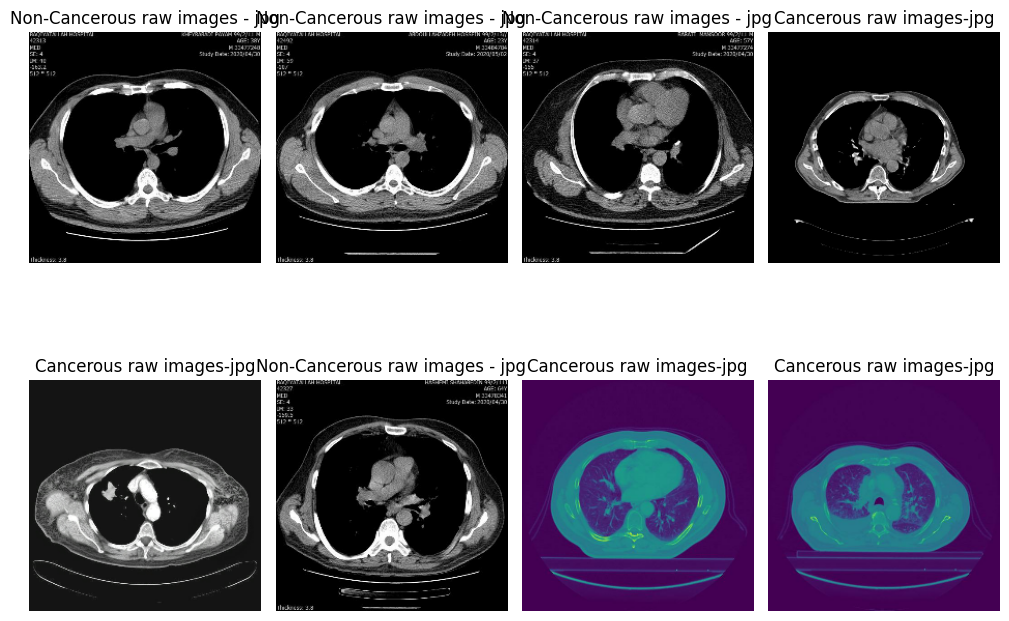

In [6]:
# ==========================================
# DISPLAY CT SAMPLES
# ==========================================

plt.figure(figsize=(10, 8))

for images, labels in ct_train_ds.take(1):

    for i in range(8):

        plt.subplot(2, 4, i + 1)

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        plt.title(ct_train_ds.class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# ==========================================
# CT DATA AUGMENTATION
# ==========================================

ct_augmentation = keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.08),
], name="ct_augmentation")

print("CT augmentation created!")

CT augmentation created!


In [8]:
# ==========================================
# CREATE CT EFFICIENTNETB0
# ==========================================

ct_base_model = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

ct_base_model.trainable = False

print("CT EfficientNetB0 loaded!")
print("Total layers:", len(ct_base_model.layers))

CT EfficientNetB0 loaded!
Total layers: 238


In [9]:
# ==========================================
# CREATE CT CLASSIFICATION MODEL
# ==========================================

ct_inputs = keras.Input(
    shape=(224, 224, 3)
)

x = ct_augmentation(ct_inputs)

x = ct_base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

ct_outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

ct_model = keras.Model(
    ct_inputs,
    ct_outputs
)

print("CT model created!")

CT model created!


In [10]:
# ==========================================
# COMPILE CT MODEL
# ==========================================

ct_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("CT model compiled!")

CT model compiled!


In [11]:
# ==========================================
# CT TRAINING CALLBACKS
# ==========================================

ct_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

ct_reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.000001
)

print("CT callbacks created!")

CT callbacks created!


In [12]:
# ==========================================
# TRAIN CT MODEL
# ==========================================

ct_history = ct_model.fit(
    ct_train_ds,
    validation_data=ct_validation_ds,
    epochs=20,
    callbacks=[
        ct_early_stopping,
        ct_reduce_lr
    ]
)

Epoch 1/20


c:\Users\srava\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


16/16 ━━━━━━━━━━━━━━━━━━━━ 15s 511ms/step - accuracy: 0.4843 - loss: 0.8084 - precision: 0.0784 - recall: 0.0455 - val_accuracy: 0.4727 - val_loss: 0.8349 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 420ms/step - accuracy: 0.4921 - loss: 0.7787 - precision: 0.0980 - recall: 0.0568 - val_accuracy: 0.4727 - val_loss: 0.7870 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 402ms/step - accuracy: 0.5433 - loss: 0.7009 - precision: 0.2308 - recall: 0.1364 - val_accuracy: 0.4909 - val_loss: 0.7438 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 430ms/step - accuracy: 0.6102 - loss: 0.6800 - precision: 0.3659 - recall: 0.1705 - val_accuracy: 0.5636 - val_loss: 0.7038 - val_precision: 0.1429 - val_recall: 0.0526 - learning_rate: 1.0000e-04
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━

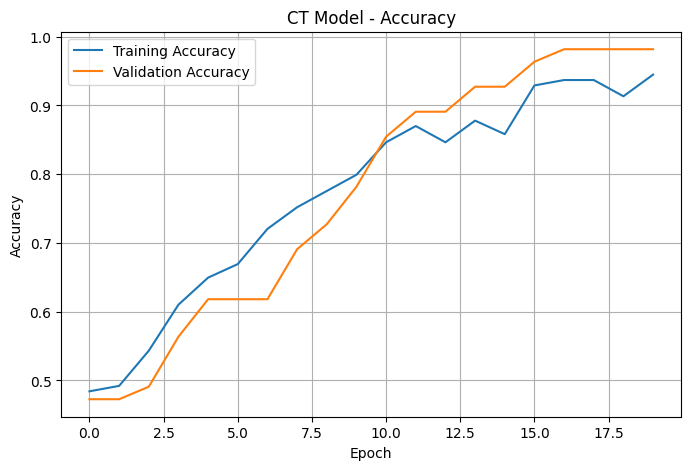

In [13]:
# ==========================================
# CT TRAINING RESULTS
# ==========================================

ct_history_dict = ct_history.history

plt.figure(figsize=(8, 5))

plt.plot(
    ct_history_dict["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    ct_history_dict["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CT Model - Accuracy")
plt.legend()
plt.grid()

plt.show()

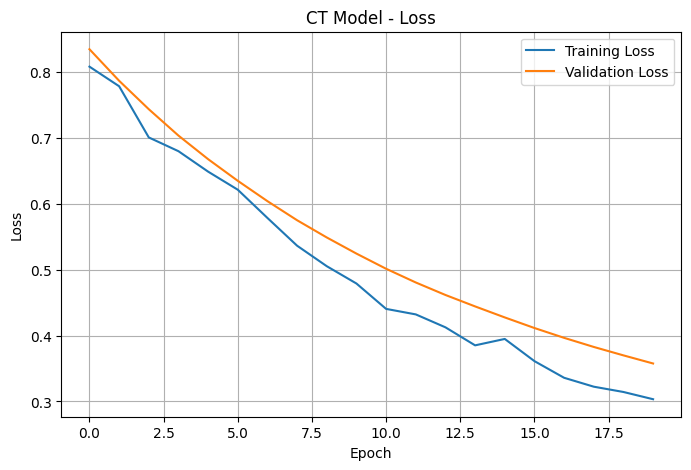

In [14]:
# ==========================================
# CT LOSS
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    ct_history_dict["loss"],
    label="Training Loss"
)

plt.plot(
    ct_history_dict["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CT Model - Loss")
plt.legend()
plt.grid()

plt.show()

In [15]:
# ==========================================
# TEST CT MODEL
# ==========================================

ct_test_results = ct_model.evaluate(
    ct_test_ds,
    verbose=1
)

print("\n========== CT TEST RESULTS ==========")
print("Test Loss      :", round(ct_test_results[0], 4))
print("Test Accuracy  :", round(ct_test_results[1], 4))
print("Test Precision :", round(ct_test_results[2], 4))
print("Test Recall    :", round(ct_test_results[3], 4))

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 340ms/step - accuracy: 0.8909 - loss: 0.4060 - precision: 0.8824 - recall: 0.7895      

========== CT TEST RESULTS ==========
Test Loss      : 0.406
Test Accuracy  : 0.8909
Test Precision : 0.8824
Test Recall    : 0.7895


In [16]:
# ==========================================
# GET CT TEST PREDICTIONS
# ==========================================

ct_y_true = []
ct_y_pred = []

for images, labels in ct_test_ds:

    predictions = ct_model.predict(
        images,
        verbose=0
    )

    predicted_labels = (
        predictions >= 0.5
    ).astype(int).flatten()

    ct_y_true.extend(labels.numpy())
    ct_y_pred.extend(predicted_labels)

ct_y_true = np.array(ct_y_true)
ct_y_pred = np.array(ct_y_pred)

print("Actual labels    :", len(ct_y_true))
print("Predicted labels :", len(ct_y_pred))

Actual labels    : 55
Predicted labels : 55


In [17]:
# ==========================================
# GET CT TEST PREDICTIONS
# ==========================================

ct_y_true = []
ct_y_pred = []

for images, labels in ct_test_ds:

    predictions = ct_model.predict(
        images,
        verbose=0
    )

    predicted_labels = (
        predictions >= 0.5
    ).astype(int).flatten()

    ct_y_true.extend(labels.numpy())
    ct_y_pred.extend(predicted_labels)

ct_y_true = np.array(ct_y_true)
ct_y_pred = np.array(ct_y_pred)

print("Actual labels    :", len(ct_y_true))
print("Predicted labels :", len(ct_y_pred))

Actual labels    : 55
Predicted labels : 55


In [18]:
# ==========================================
# CT CONFUSION MATRIX
# ==========================================

ct_confusion_matrix = tf.math.confusion_matrix(
    ct_y_true,
    ct_y_pred,
    num_classes=2
).numpy()

print("CT Confusion Matrix:")
print(ct_confusion_matrix)

CT Confusion Matrix:
[[34  2]
 [ 4 15]]


In [19]:
print(ct_train_ds.class_names)

['Cancerous raw images-jpg', 'Non-Cancerous raw images - jpg']


In [20]:
# ==========================================
# CT F1 SCORE
# ==========================================

TN = ct_confusion_matrix[0][0]
FP = ct_confusion_matrix[0][1]
FN = ct_confusion_matrix[1][0]
TP = ct_confusion_matrix[1][1]

precision = (
    TP / (TP + FP)
    if (TP + FP) != 0
    else 0
)

recall = (
    TP / (TP + FN)
    if (TP + FN) != 0
    else 0
)

f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) != 0
    else 0
)

print("========== CT FINAL METRICS ==========")
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1 Score  :", round(f1, 4))

========== CT FINAL METRICS ==========
Precision : 0.8824
Recall    : 0.7895
F1 Score  : 0.8333


In [21]:
# ==========================================
# CT F1 SCORE
# ==========================================

TN = ct_confusion_matrix[0][0]
FP = ct_confusion_matrix[0][1]
FN = ct_confusion_matrix[1][0]
TP = ct_confusion_matrix[1][1]

precision = (
    TP / (TP + FP)
    if (TP + FP) != 0
    else 0
)

recall = (
    TP / (TP + FN)
    if (TP + FN) != 0
    else 0
)

f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) != 0
    else 0
)

print("========== CT FINAL METRICS ==========")
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1 Score  :", round(f1, 4))

========== CT FINAL METRICS ==========
Precision : 0.8824
Recall    : 0.7895
F1 Score  : 0.8333


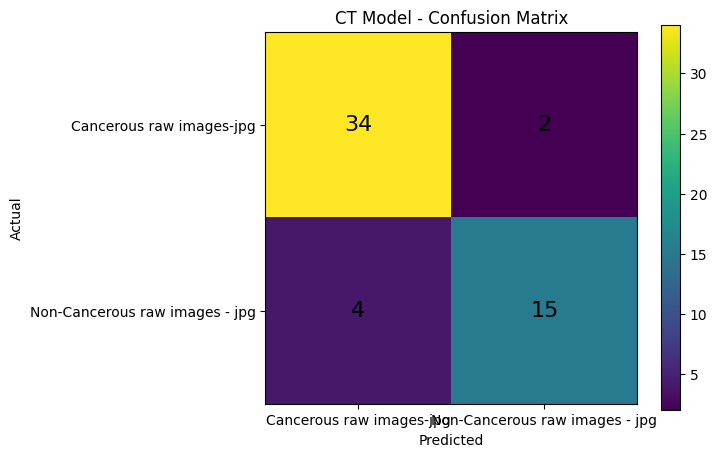

In [22]:
# ==========================================
# DISPLAY CT CONFUSION MATRIX
# ==========================================

plt.figure(figsize=(6, 5))

plt.imshow(ct_confusion_matrix)

plt.title("CT Model - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ct_train_ds.class_names
)

plt.yticks(
    [0, 1],
    ct_train_ds.class_names
)

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            ct_confusion_matrix[i][j],
            ha="center",
            va="center",
            fontsize=16
        )

plt.colorbar()
plt.show()

In [23]:
# ==========================================
# SAVE INITIAL CT MODEL
# ==========================================

ct_model.save(
    "lung_ct_efficientnet_initial.keras"
)

print("Initial CT model saved successfully!")

Initial CT model saved successfully!


In [ ]:
# delete
# ==========================================
# CHECK ACTUAL CT TEST FILES
# ==========================================

for class_name in os.listdir(ct_test_dir):

    folder = os.path.join(ct_test_dir, class_name)

    if os.path.isdir(folder):

        files = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(class_name, ":", len(files))

Cancerous raw images-jpg : 36
Non-Cancerous raw images - jpg : 19


In [25]:
# ==========================================
# CHECK TENSORFLOW DATASET
# ==========================================

print("Classes:", ct_test_ds.class_names)

print(
    "Number of batches:",
    tf.data.experimental.cardinality(ct_test_ds).numpy()
)

print(
    "Batch size:",
    BATCH_SIZE
)

Classes: ['Cancerous raw images-jpg', 'Non-Cancerous raw images - jpg']
Number of batches: 4
Batch size: 16


In [26]:
# ==========================================
# LIST CT TEST FILES
# ==========================================

for class_name in os.listdir(ct_test_dir):

    folder = os.path.join(ct_test_dir, class_name)

    if os.path.isdir(folder):

        files = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print("\n", class_name)
        print("Count:", len(files))

        for f in sorted(files):
            print(f)


 Cancerous raw images-jpg
Count: 36
Cancerous1.jpg
Cancerous100.jpg
Cancerous109.jpg
Cancerous110.jpg
Cancerous116.jpg
Cancerous12.jpg
Cancerous124.jpg
Cancerous129.jpg
Cancerous136.jpg
Cancerous146.jpg
Cancerous147.jpg
Cancerous157.jpg
Cancerous16.jpg
Cancerous162.jpg
Cancerous176.jpg
Cancerous178.jpg
Cancerous197.jpg
Cancerous198.jpg
Cancerous200.jpg
Cancerous211.jpg
Cancerous215.jpg
Cancerous226.jpg
Cancerous228.jpg
Cancerous238.jpg
Cancerous30.jpg
Cancerous31.jpg
Cancerous42.jpg
Cancerous47.jpg
Cancerous5.jpg
Cancerous55.jpg
Cancerous62.jpg
Cancerous76.jpg
Cancerous8.jpg
Cancerous81.jpg
Cancerous91.jpg
Cancerous93.jpg

 Non-Cancerous raw images - jpg
Count: 19
Non-Cancerous107.jpg
Non-Cancerous108.jpg
Non-Cancerous114.jpg
Non-Cancerous116.jpg
Non-Cancerous125.jpg
Non-Cancerous126.jpg
Non-Cancerous16.jpg
Non-Cancerous17.jpg
Non-Cancerous18.jpg
Non-Cancerous21.jpg
Non-Cancerous23.jpg
Non-Cancerous3.jpg
Non-Cancerous36.jpg
Non-Cancerous48.jpg
Non-Cancerous65.jpg
Non-Cancerous67.jpg
N

In [32]:


ct_output = "processed_data/lung_ct"

ct_classes = ct_train_ds.class_names

print("CT output folder:", ct_output)
print("CT classes:", ct_classes)

CT output folder: processed_data/lung_ct
CT classes: ['Cancerous raw images-jpg', 'Non-Cancerous raw images - jpg']


In [ ]:
# ==========================================
# CHECK ALL CT SPLIT COUNTS
# ==========================================

for split in ["train", "validation", "test"]:

    print("\n==========", split.upper(), "==========")

    total = 0

    for class_name in ct_classes:

        folder = os.path.join(
            ct_output,
            split,
            class_name
        )

        files = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(class_name, ":", len(files))

        total += len(files)

    print("Total:", total)
# delete


========== TRAIN ==========
Cancerous raw images-jpg : 166
Non-Cancerous raw images - jpg : 88
Total: 254

========== VALIDATION ==========
Cancerous raw images-jpg : 36
Non-Cancerous raw images - jpg : 19
Total: 55

========== TEST ==========
Cancerous raw images-jpg : 36
Non-Cancerous raw images - jpg : 19
Total: 55


In [34]:
# ==========================================
# CT MODEL - TEST EVALUATION
# ==========================================

ct_test_loss, ct_test_accuracy, ct_test_precision, ct_test_recall = ct_model.evaluate(
    ct_test_ds
)

print("CT Test Accuracy :", ct_test_accuracy)
print("CT Test Precision:", ct_test_precision)
print("CT Test Recall   :", ct_test_recall)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 238ms/step - accuracy: 0.8909 - loss: 0.4060 - precision: 0.8824 - recall: 0.7895      
CT Test Accuracy : 0.8909090757369995
CT Test Precision: 0.8823529481887817
CT Test Recall   : 0.7894737124443054


In [35]:
# ==========================================
# CT MODEL - FINE TUNING
# ==========================================

ct_base_model.trainable = True

# Freeze all layers except the last 20
for layer in ct_base_model.layers[:-20]:
    layer.trainable = False

print("CT base model is now ready for fine-tuning.")

CT base model is now ready for fine-tuning.


In [36]:
# ==========================================
# RECOMPILE CT MODEL
# ==========================================

ct_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("CT model recompiled successfully.")

CT model recompiled successfully.


In [38]:
# ==========================================
# CT MODEL - CALLBACKS
# ==========================================

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.000001
)

print("Callbacks created successfully!")

Callbacks created successfully!


In [39]:
# ==========================================
# TRAIN CT MODEL - FINE TUNING
# ==========================================

ct_fine_history = ct_model.fit(
    ct_train_ds,
    validation_data=ct_validation_ds,
    epochs=10,
    callbacks=[
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/10


c:\Users\srava\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


16/16 ━━━━━━━━━━━━━━━━━━━━ 17s 571ms/step - accuracy: 0.6260 - loss: 0.5987 - precision: 0.4809 - recall: 1.0000 - val_accuracy: 0.9818 - val_loss: 0.3497 - val_precision: 0.9500 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 475ms/step - accuracy: 0.7717 - loss: 0.5130 - precision: 0.6027 - recall: 1.0000 - val_accuracy: 0.9818 - val_loss: 0.3413 - val_precision: 0.9500 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 481ms/step - accuracy: 0.7835 - loss: 0.4891 - precision: 0.6154 - recall: 1.0000 - val_accuracy: 0.9818 - val_loss: 0.3322 - val_precision: 0.9500 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 479ms/step - accuracy: 0.8504 - loss: 0.4190 - precision: 0.6984 - recall: 1.0000 - val_accuracy: 0.9818 - val_loss: 0.3211 - val_precision: 0.9500 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 492ms/step - accu

In [40]:
# ==========================================
# FINE-TUNED CT MODEL - TEST EVALUATION
# ==========================================

ct_final_loss, ct_final_accuracy, ct_final_precision, ct_final_recall = ct_model.evaluate(
    ct_test_ds
)

print("Final CT Test Accuracy :", ct_final_accuracy)
print("Final CT Test Precision:", ct_final_precision)
print("Final CT Test Recall   :", ct_final_recall)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 228ms/step - accuracy: 0.9636 - loss: 0.2684 - precision: 0.9048 - recall: 1.0000      
Final CT Test Accuracy : 0.9636363387107849
Final CT Test Precision: 0.9047619104385376
Final CT Test Recall   : 1.0


In [41]:
# ==========================================
# CT FINAL MODEL - PREDICTIONS
# ==========================================

import numpy as np

y_true = []
y_pred = []

for images, labels in ct_test_ds:
    
    predictions = ct_model.predict(images, verbose=0)
    
    y_true.extend(labels.numpy())
    y_pred.extend((predictions >= 0.5).astype(int).flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Actual labels   :", len(y_true))
print("Predicted labels:", len(y_pred))

Actual labels   : 55
Predicted labels: 55


Confusion Matrix:
[[34  2]
 [ 0 19]]

F1 Score: 0.95

Classification Report:
                                precision    recall  f1-score   support

      Cancerous raw images-jpg       1.00      0.94      0.97        36
Non-Cancerous raw images - jpg       0.90      1.00      0.95        19

                      accuracy                           0.96        55
                     macro avg       0.95      0.97      0.96        55
                  weighted avg       0.97      0.96      0.96        55



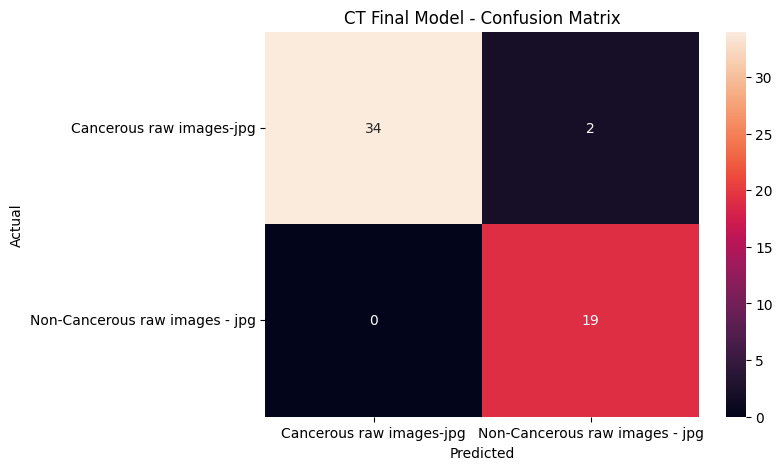

In [42]:
# ==========================================
# CT FINAL MODEL - CONFUSION MATRIX
# ==========================================

from sklearn.metrics import confusion_matrix, classification_report, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nF1 Score:", f1_score(y_true, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=ct_test_ds.class_names
    )
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=ct_test_ds.class_names,
    yticklabels=ct_test_ds.class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CT Final Model - Confusion Matrix")
plt.show()

In [43]:
# ==========================================
# SAVE FINAL CT MODEL
# ==========================================

ct_model.save("lung_ct_efficientnet_final.keras")

print("Final CT model saved successfully!")

Final CT model saved successfully!
